
Ba-133 disk source -> Si interaction rate calculator + plots (paste NIST HTML tables)

Model per line i:
  R_int,i = A * I_i * fΩ * T_Total(E_i) * P_int,Si(E_i) * eps
  where T_Total = T_Fe(E_i) * T_Al(E_i)  (if Fe layer present)
        T_Total = T_Al(E_i)              (if no Fe layer)

Geometry:
  - d_cm: distance from source center to Al lid (cm)
    * d_cm = 0  => fΩ = 1/2 (hemisphere limit, source taped to lid)
    * d_cm > 0  => source is separated from lid, fΩ < 1/2 (reduced solid angle)
  - Fe layer thickness x_Fe is a parameter (default 0 mm, i.e., no Fe layer)
    * If x_Fe > 0: Source -> [taped to Fe] -> [gap d_fe_al] -> Al -> Si
    * If x_Fe = 0: Source -> Al -> Si (original behavior)
  - d_fe_al: Distance between Fe layer and Al lid (gap, in cm)
    * Only relevant when x_Fe > 0
    * Accounts for the gap between Fe and Al layers
  - Al lid thickness x_Al is a parameter (default 0.87 mm)
  - Si thickness t_Si is a parameter (default 675 um)
  - Uses NIST XCOM tables (μ/ρ and μen/ρ) pasted as text blocks
  - Log-log interpolation in energy

NOTE:
  - The Barium (Z=56) table is NOT used for lid/Si transport.
    All we need is Fe (Z=26), Al (Z=13), and Si (Z=14).


In [1]:
from __future__ import annotations
import math
import re
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import numpy as np
import matplotlib.pyplot as plt

In [2]:
# -------------------------
# User-editable: NIST tables pasted as text
# -------------------------

NIST_AL_TEXT = r"""
Energy      μ/ρ       μen/ρ
(MeV)   (cm2/g)   (cm2/g)
1.00000E-03 1.185E+03 1.183E+03
1.50000E-03 4.022E+02 4.001E+02
1.55960E-03 3.621E+02 3.600E+02
1.55960E-03 3.957E+03 3.829E+03
2.00000E-03 2.263E+03 2.204E+03
3.00000E-03 7.880E+02 7.732E+02
4.00000E-03 3.605E+02 3.545E+02
5.00000E-03 1.934E+02 1.902E+02
6.00000E-03 1.153E+02 1.133E+02
8.00000E-03 5.033E+01 4.918E+01
1.00000E-02 2.623E+01 2.543E+01
1.50000E-02 7.955E+00 7.487E+00
2.00000E-02 3.441E+00 3.094E+00
3.00000E-02 1.128E+00 8.778E-01
4.00000E-02 5.685E-01 3.601E-01
5.00000E-02 3.681E-01 1.840E-01
6.00000E-02 2.778E-01 1.099E-01
8.00000E-02 2.018E-01 5.511E-02
1.00000E-01 1.704E-01 3.794E-02
1.50000E-01 1.378E-01 2.827E-02
2.00000E-01 1.223E-01 2.745E-02
3.00000E-01 1.042E-01 2.816E-02
4.00000E-01 9.276E-02 2.862E-02
5.00000E-01 8.445E-02 2.868E-02
6.00000E-01 7.802E-02 2.851E-02
8.00000E-01 6.841E-02 2.778E-02
1.00000E+00 6.146E-02 2.686E-02
"""

NIST_SI_TEXT = r"""
Energy      μ/ρ       μen/ρ
(MeV)   (cm2/g)   (cm2/g)
1.00000E-03	1.570E+03	1.567E+03
1.50000E-03	5.355E+02	5.331E+02
1.83890E-03	3.092E+02	3.070E+02
1.83890E-03	3.192E+03	3.059E+03
2.00000E-03	2.777E+03	2.669E+03
3.00000E-03	9.784E+02	9.516E+02
4.00000E-03	4.529E+02	4.427E+02
5.00000E-03	2.450E+02	2.400E+02
6.00000E-03	1.470E+02	1.439E+02
8.00000E-03	6.468E+01	6.313E+01
1.00000E-02	3.389E+01	3.289E+01
1.50000E-02	1.034E+01	9.794E+00
2.00000E-02	4.464E+00	4.076E+00
3.00000E-02	1.436E+00	1.164E+00
4.00000E-02	7.012E-01	4.782E-01
5.00000E-02	4.385E-01	2.430E-01
6.00000E-02	3.207E-01	1.434E-01
8.00000E-02	2.228E-01	6.896E-02
1.00000E-01	1.835E-01	4.513E-02
1.50000E-01	1.448E-01	3.086E-02
2.00000E-01	1.275E-01	2.905E-02
3.00000E-01	1.082E-01	2.932E-02
4.00000E-01	9.614E-02	2.968E-02
5.00000E-01	8.748E-02	2.971E-02
6.00000E-01	8.077E-02	2.951E-02
8.00000E-01	7.082E-02	2.875E-02
1.00000E+00	6.361E-02	2.778E-02
1.25000E+00	5.688E-02	2.652E-02
1.50000E+00	5.183E-02	2.535E-02
2.00000E+00	4.480E-02	2.345E-02
3.00000E+00	3.678E-02	2.101E-02
4.00000E+00	3.240E-02	1.963E-02
5.00000E+00	2.967E-02	1.878E-02
6.00000E+00	2.788E-02	1.827E-02
8.00000E+00	2.574E-02	1.773E-02
1.00000E+01	2.462E-02	1.753E-02
1.50000E+01	2.352E-02	1.746E-02
2.00000E+01	2.338E-02	1.757E-02
"""

NIST_Fe_TEXT = r"""
Energy      μ/ρ       μen/ρ
(MeV)   (cm2/g)   (cm2/g)
1.00000E-03	9.085E+03	9.052E+03
1.50000E-03	3.399E+03	3.388E+03
2.00000E-03	1.626E+03	1.620E+03
3.00000E-03	5.576E+02	5.535E+02
4.00000E-03	2.567E+02	2.536E+02
5.00000E-03	1.398E+02	1.372E+02
6.00000E-03	8.484E+01	8.265E+01
7.11200E-03	5.319E+01	5.133E+01
7.11200E-03	4.076E+02	2.978E+02
8.00000E-03	3.056E+02	2.316E+02
1.00000E-02	1.706E+02	1.369E+02
1.50000E-02	5.708E+01	4.896E+01
2.00000E-02	2.568E+01	2.260E+01
3.00000E-02	8.176E+00	7.251E+00
4.00000E-02	3.629E+00	3.155E+00
5.00000E-02	1.958E+00	1.638E+00
6.00000E-02	1.205E+00	9.555E-01
8.00000E-02	5.952E-01	4.104E-01
1.00000E-01	3.717E-01	2.177E-01
1.50000E-01	1.964E-01	7.961E-02
2.00000E-01	1.460E-01	4.825E-02
3.00000E-01	1.099E-01	3.361E-02
4.00000E-01	9.400E-02	3.039E-02
5.00000E-01	8.414E-02	2.914E-02
6.00000E-01	7.704E-02	2.836E-02
8.00000E-01	6.699E-02	2.714E-02
1.00000E+00	5.995E-02	2.603E-02
1.25000E+00	5.350E-02	2.472E-02
1.50000E+00	4.883E-02	2.360E-02
2.00000E+00	4.265E-02	2.199E-02
3.00000E+00	3.621E-02	2.042E-02
4.00000E+00	3.312E-02	1.990E-02
5.00000E+00	3.146E-02	1.983E-02
6.00000E+00	3.057E-02	1.997E-02
8.00000E+00	2.991E-02	2.050E-02
1.00000E+01	2.994E-02	2.108E-02
1.50000E+01	3.092E-02	2.221E-02
2.00000E+01	3.224E-02	2.292E-02
"""

In [3]:
@dataclass
class XCOMTable:
    E_keV: np.ndarray
    mu_over_rho: np.ndarray     # cm^2/g
    mu_en_over_rho: np.ndarray  # cm^2/g

    def _interp_loglog(self, y: np.ndarray, E_keV: float) -> float:
        E = self.E_keV
        if E_keV < E[0] or E_keV > E[-1]:
            raise ValueError(f"E={E_keV} keV outside table [{E[0]}, {E[-1]}] keV")

        idx = int(np.searchsorted(E, E_keV))
        if idx == 0:
            return float(y[0])
        if idx >= len(E):
            return float(y[-1])

        E1, E2 = float(E[idx-1]), float(E[idx])
        y1, y2 = float(y[idx-1]), float(y[idx])

        if abs(E2 - E_keV) < 1e-14:
            return y2

        t = math.log(E_keV/E1) / math.log(E2/E1)
        return math.exp(math.log(y1) + t*(math.log(y2)-math.log(y1)))

    def mu_over_rho_at(self, E_keV: float) -> float:
        return self._interp_loglog(self.mu_over_rho, E_keV)

    def mu_en_over_rho_at(self, E_keV: float) -> float:
        return self._interp_loglog(self.mu_en_over_rho, E_keV)


def parse_nist_xcom_text(text: str) -> XCOMTable:
    rows = []
    for line in text.splitlines():
        nums = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", line)
        if len(nums) >= 3:
            E_MeV = float(nums[0])
            mu = float(nums[1])
            muen = float(nums[2])
            if E_MeV > 0 and mu > 0:
                rows.append((E_MeV*1e3, mu, muen))  # keV

    if len(rows) < 10:
        raise ValueError("Too few numeric rows parsed. Did you paste the NIST table correctly?")

    rows.sort(key=lambda r: r[0])
    E = np.array([r[0] for r in rows], dtype=float)
    mu = np.array([r[1] for r in rows], dtype=float)
    muen = np.array([r[2] for r in rows], dtype=float)

    # deduplicate energies
    uniqE, idx = np.unique(E, return_index=True)
    return XCOMTable(E_keV=E[idx], mu_over_rho=mu[idx], mu_en_over_rho=muen[idx])


xcom_al = parse_nist_xcom_text(NIST_AL_TEXT)
xcom_si = parse_nist_xcom_text(NIST_SI_TEXT)
xcom_fe = parse_nist_xcom_text(NIST_Fe_TEXT)

print("Parsed Al rows:", len(xcom_al.E_keV), "Energy range (keV):", (xcom_al.E_keV[0], xcom_al.E_keV[-1]))
print("Parsed Si rows:", len(xcom_si.E_keV), "Energy range (keV):", (xcom_si.E_keV[0], xcom_si.E_keV[-1]))
print("Parsed Fe rows:", len(xcom_fe.E_keV), "Energy range (keV):", (xcom_fe.E_keV[0], xcom_fe.E_keV[-1]))

Parsed Al rows: 26 Energy range (keV): (np.float64(1.0), np.float64(1000.0))
Parsed Si rows: 37 Energy range (keV): (np.float64(1.0), np.float64(20000.0))
Parsed Fe rows: 37 Energy range (keV): (np.float64(1.0), np.float64(20000.0))


In [23]:
# -------------------------
# Materials and geometry defaults
# -------------------------
RHO_AL = 2.70  # g/cm^3
RHO_SI = 2.33  # g/cm^3
RHO_FE = 7.87  # g/cm^3

DEFAULTS = dict(
    activity_kBq=2.5,      # kBq
    disk_diam_cm=2.5,      # cm (source disk diameter)
    d_cm=0.0,              # cm (distance from source center to Al lid)
                          #     d_cm=0.0 => source taped to lid (hemisphere, fΩ=0.5)
                          #     d_cm>0.0 => source separated from lid (fΩ<0.5)
    x_al_mm=0.87,          # mm (Al lid thickness)
    t_si_um=675.0,         # um (Si detector thickness)
    eps=1.0                # extra efficiency factor
)

# Ba-133 lines (energy keV, intensity %), from nndc.bnl.gov
BA133_LINES = [
    ("XR1",      4.290,   15.700),
    ("XR Ka2",  30.625,   33.900),
    ("XR Ka1",  30.973,   62.200),
    ("XR Kb3",  34.920,    5.880),
    ("XR Kb1",  34.987,   11.400),
    ("XR Kb2",  35.818,    3.510),
    ("g",       53.162,    2.140),
    ("g",       79.614,    2.650),
    ("g",       80.998,   32.900),
    ("g",      160.612,    0.638),
    ("g",      223.237,    0.453),
    ("g",      276.399,    7.160),
    ("g",      302.851,   18.340),
    ("g",      356.013,   62.050),
    ("g",      383.849,    8.940),
]

AM241_LINES = [
    ("L3-M1", 11.87, 0.837),
    ("L3-M2", 12.24, 0.0260),
    ("L3-M3", 13.18, 0.0199),
    ("L3-M4", 13.76, 1.398),
    ("L3-M5", 13.95, 11.60),
    ("L2-M1", 15.86, 0.404),
    ("L3-N1", 16.11, 0.248),
    ("L3-N5", 16.79, 0.339),
    ("L3-N4", 16.84, 2.451),
    ("L1-M2", 17.06, 1.736),
    ("L3-O1", 17.27, 0.594),
    ("L3-O4,5", 17.50, 0.594),
    ("L2-M4", 17.75, 11.83),
    ("L1-M3", 17.99, 1.310),
    ("L1-M4", 18.58, 0.054),
    ("L1-M5", 18.76, 0.047),
    ("L2-N1", 20.10, 0.087),
    ("L2-N4", 20.78, 2.94),
    ("L1-N2", 21.10, 0.467),
    ("L2-O1", 21.26, 0.520),
    ("L1-N3", 21.34, 0.520),
    ("L2-O4", 21.49, 0.567),
    ("L1-O1,2", 22.12, 0.173),
    ("L1-P2", 22.40, 0.069),
]


def mm_to_cm(x_mm: float) -> float:
    return x_mm / 10.0

def um_to_cm(x_um: float) -> float:
    return x_um * 1e-4

def kBq_to_Bq(x_kBq: float) -> float:
    return x_kBq * 1e3

In [68]:
# def f_omega_disk(a_cm: float, d_cm: float) -> float:
#     # d=0 => hemisphere limit
#     if d_cm <= 0:
#         return 0.5
#     return 0.5*(1 - d_cm/math.sqrt(d_cm*d_cm + a_cm*a_cm))

# def transmission(mu_over_rho: float, rho: float, x_cm: float) -> float:
#     return math.exp(-mu_over_rho * rho * x_cm)

# def p_interact(mu_over_rho: float, rho: float, t_cm: float) -> float:
#     return 1 - math.exp(-mu_over_rho * rho * t_cm)

# def compute_rates(
#     activity_kBq=2.5,
#     disk_diam_cm=2.5,
#     d_cm=10.0,
#     x_al_mm=0.7,
#     t_si_um=675.0,
#     eps=1.0
# ):
#     A = kBq_to_Bq(activity_kBq)
#     a_cm = disk_diam_cm/2
#     fO = f_omega_disk(a_cm, d_cm)

#     x_al_cm = mm_to_cm(x_al_mm)
#     t_si_cm = um_to_cm(t_si_um)

#     rows = []
#     for lab, E_keV, inten_pct in BA133_LINES:
#         I = inten_pct/100
#         muor_al = xcom_al.mu_over_rho_at(E_keV)
#         muor_si = xcom_si.mu_over_rho_at(E_keV)

#         T_al = transmission(muor_al, RHO_AL, x_al_cm)
#         P_si = p_interact(muor_si, RHO_SI, t_si_cm)

#         photons_emit = A * I
#         photons_after_al = photons_emit * fO * T_al
#         interactions = photons_after_al * P_si * eps

#         rows.append((lab, E_keV, inten_pct, T_al, P_si, photons_after_al, interactions, interactions*3600))

#     rows.sort(key=lambda r: r[1])
#     return fO, rows

# # Run with your default setup
# fO, rows = compute_rates()
# print("fΩ =", fO)
# for r in rows[:5]:
#     print(r)
# print("Total interactions/s =", sum(r[6] for r in rows))

# --- Geometry: forward-hemisphere normalized (2π) ---
# g(d) = fraction of forward (2π) emission that hits a finite 10x10 cm detector,
# averaged over a finite disk source (diameter disk_diam_cm) at distance d_cm (on-axis).
#
# With this convention:
#   - g(d->0) -> 1   (detector captures essentially all forward emission)
#   - In the rate, use photons_front = (A*I)/2, then multiply by g(d)

def omega_rect_offaxis(a: float, b: float, d: float, x0: float, y0: float) -> float:
    """
    Solid angle Ω of a rectangle (half-sides a,b) in plane z=0,
    as seen from point (x0, y0, z=d). Exact closed form.

    Returns Ω in steradians.
    """
    # shifted bounds relative to point
    X1, X2 = -a - x0, a - x0
    Y1, Y2 = -b - y0, b - y0

    def F(X, Y):
        R = math.sqrt(d*d + X*X + Y*Y)
        return math.atan2(X*Y, d*R)  # atan( (X Y) / (d R) )

    return (F(X2, Y2) - F(X1, Y2) - F(X2, Y1) + F(X1, Y1))


def g_geom_disk_to_square(
    d_cm: float,
    disk_diam_cm: float,
    det_L_cm: float = 10.0,
    n_r: int = 60,
    n_phi: int = 120,
) -> float:
    """
    Geometry factor normalized to forward hemisphere (2π):
      g(d) = < Ω_det(x0,y0; d) / (2π) > averaged over source disk area.

    Uses deterministic numerical quadrature on (ρ, φ) (still "analytic integrand").
    - d_cm: distance from source plane to detector plane
    - disk_diam_cm: source disk diameter
    - det_L_cm: detector side length (square)
    """
    if d_cm <= 0:
        return 1.0  # forward hemisphere fully covered in the contact limit (for this large detector)

    a_det = det_L_cm / 2.0
    b_det = det_L_cm / 2.0
    a_src = disk_diam_cm / 2.0

    # mid-point grid in rho and phi for stable integration
    rho_edges = np.linspace(0.0, a_src, n_r + 1)
    rho = 0.5 * (rho_edges[:-1] + rho_edges[1:])
    dr = rho_edges[1:] - rho_edges[:-1]

    phi_edges = np.linspace(0.0, 2.0 * math.pi, n_phi + 1)
    phi = 0.5 * (phi_edges[:-1] + phi_edges[1:])
    dphi = phi_edges[1:] - phi_edges[:-1]

    # area normalization
    A_src = math.pi * a_src * a_src

    acc = 0.0
    for i in range(n_r):
        for j in range(n_phi):
            x0 = rho[i] * math.cos(phi[j])
            y0 = rho[i] * math.sin(phi[j])

            Omega = omega_rect_offaxis(a_det, b_det, d_cm, x0, y0)  # steradians
            g_point = Omega / (2.0 * math.pi)                       # fraction of forward hemisphere

            # dA in polar coords = ρ dρ dφ
            dA = rho[i] * dr[i] * dphi[j]
            acc += g_point * dA

    return acc / A_src


def transmission(mu_over_rho: float, rho: float, x_cm: float) -> float:
    return math.exp(-mu_over_rho * rho * x_cm)


def p_interact(mu_over_rho: float, rho: float, t_cm: float) -> float:
    return 1 - math.exp(-mu_over_rho * rho * t_cm)


def compute_rates(
    activity_kBq=0.3,
    disk_diam_cm=2.5,
    d_cm=0.0,  # Distance from source to Al lid (or to Fe if Fe layer present)
    x_al_mm=0.7,
    # x_fe_mm=12.5,  # Fe layer thickness (0 = no Fe layer)
    # d_fe_al_cm=20.0,  # NEW: Distance between Fe layer and Al lid (gap)
    x_fe_mm=0,  # Fe layer thickness (0 = no Fe layer)
    d_fe_al_cm=0.0,  # NEW: Distance between Fe layer and Al lid (gap)
    t_si_um=675.0,
    eps=1.0,
    det_L_cm=10.0,
    n_r=60,
    n_phi=120,
):
    """
    Compute interaction rates for Ba-133 source.
    
    Geometry:
    - If x_fe_mm = 0: Source -> [gap d_cm] -> Al -> Si
    - If x_fe_mm > 0: Source -> [taped to Fe at d_cm] -> [gap d_fe_al_cm] -> Al -> Si
                      Typically d_cm=0 if source is taped to Fe
    
    The geometry factor is calculated for the total distance from source to detector plane:
    - Without Fe: d_total = d_cm + x_al_cm (to detector plane after Al)
    - With Fe: d_total = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm (to detector plane after Al)
    
    Returns:
        g: geometry factor
        rows: list of (label, E_keV, intensity%, T_Fe, T_Al, T_total, P_Si, photons_after, interactions/s, interactions/hr)
    """
    A = kBq_to_Bq(activity_kBq)

    x_al_cm = mm_to_cm(x_al_mm)
    x_fe_cm = mm_to_cm(x_fe_mm) if x_fe_mm > 0 else 0.0
    t_si_cm = um_to_cm(t_si_um)
    
    # Calculate total distance from source to detector plane for geometry factor
    if x_fe_mm > 0:
        # Source -> Fe (d_cm, typically 0 if taped) -> gap (d_fe_al_cm) -> Al -> detector
        d_total_cm = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm
    else:
        # Source -> gap (d_cm) -> Al -> detector
        d_total_cm = d_cm + x_al_cm
    
    # geometry factor (2π-normalized, includes finite detector AND finite disk)
    # Calculated for total distance from source to detector plane
    g = g_geom_disk_to_square(
        d_cm=d_total_cm,
        disk_diam_cm=disk_diam_cm,
        det_L_cm=det_L_cm,
        n_r=n_r,
        n_phi=n_phi,
    )

    rows = []
    # for lab, E_keV, inten_pct in BA133_LINES:
    for lab, E_keV, inten_pct in AM241_LINES:
        I = inten_pct / 100.0
        muor_al = xcom_al.mu_over_rho_at(E_keV)
        muor_si = xcom_si.mu_over_rho_at(E_keV)
        
        # Calculate transmissions
        T_al = transmission(muor_al, RHO_AL, x_al_cm)
        
        # Fe transmission (if Fe layer present)
        if x_fe_mm > 0:
            muor_fe = xcom_fe.mu_over_rho_at(E_keV)
            T_fe = transmission(muor_fe, RHO_FE, x_fe_cm)
            T_total = T_fe * T_al  # Combined transmission through Fe + Al
        else:
            T_fe = 1.0  # No Fe layer
            T_total = T_al  # Only Al transmission
        
        P_si = p_interact(muor_si, RHO_SI, t_si_cm)

        photons_emit = A * I
        photons_front = 0.5 * photons_emit          # emission into forward hemisphere (2π)
        # Geometry factor accounts for total distance (source -> Fe -> gap -> Al -> detector)
        # Transmission accounts for attenuation through Fe and Al layers
        photons_after = photons_front * g * T_total  # finite geometry + Fe+Al transmission
        interactions = photons_after * P_si * eps

        # Return: (label, E_keV, intensity%, T_fe, T_al, T_total, P_si, photons_after, interactions/s, interactions/hr)
        rows.append((lab, E_keV, inten_pct, T_fe, T_al, T_total, P_si, photons_after, interactions, interactions * 3600))

    rows.sort(key=lambda r: r[1])
    return g, rows


# Run with your default setup (no Fe layer)
g, rows = compute_rates()
print("g (fraction of forward 2π that hits detector) =", g)
for r in rows[:5]:
    print(r)
print("Total interactions/s =", sum(r[8] for r in rows))  # interactions/s is at index 8


g (fraction of forward 2π that hits detector) = 0.9871419525321224
('L3-M1', 11.87, 0.837, 1.0, 0.05010982386639166, 0.05010982386639166, 0.9603116414956867, np.float64(0.06210394701718706), np.float64(0.05963914330343606), np.float64(214.7009158923698))
('L3-M2', 12.24, 0.026, 1.0, 0.06489352971559294, 0.06489352971559294, 0.947627322040995, np.float64(0.002498305899575917), np.float64(0.002367462929254345), np.float64(8.522866545315642))
('L3-M3', 13.18, 0.0199, 1.0, 0.11081449817852367, 0.11081449817852367, 0.9069780897192845, np.float64(0.003265280757009333), np.float64(0.002961538103389464), np.float64(10.66153717220207))
('L3-M4', 13.76, 1.398, 1.0, 0.14398262308555573, 0.14398262308555573, 0.8767558842152045, np.float64(0.29804931027203135), np.float64(0.2613164865672867), np.float64(940.739351642232))
('L3-M5', 13.95, 11.6, 1.0, 0.15545289793787093, 0.15545289793787093, 0.8661713906892199, np.float64(2.6701009432306995), np.float64(2.3127650472787327), np.float64(8325.954170203

Line     E (keV)    Int%       T_Fe       T_Al    T_Total       P_Si       Phot/s        Int/s       Int/hr
--------------------------------------------------------------------------------------------------------------
L3-M1     11.870   0.837          1    0.05011    0.05011     0.9603       0.0621      0.05964        214.7
L3-M2     12.240   0.026          1    0.06489    0.06489     0.9476     0.002498     0.002367        8.523
L3-M3     13.180   0.020          1     0.1108     0.1108      0.907     0.003265     0.002962        10.66
L3-M4     13.760   1.398          1      0.144      0.144     0.8768        0.298       0.2613        940.7
L3-M5     13.950  11.600          1     0.1555     0.1555     0.8662         2.67        2.313         8326
L2-M1     15.860   0.404          1     0.2786     0.2786     0.7489       0.1666       0.1248        449.3
L3-N1     16.110   0.248          1     0.2949     0.2949     0.7329       0.1083      0.07936        285.7
L3-N5     16.790   0.339 

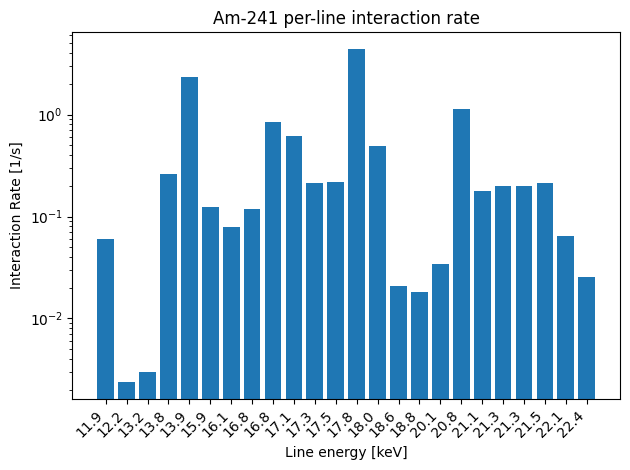

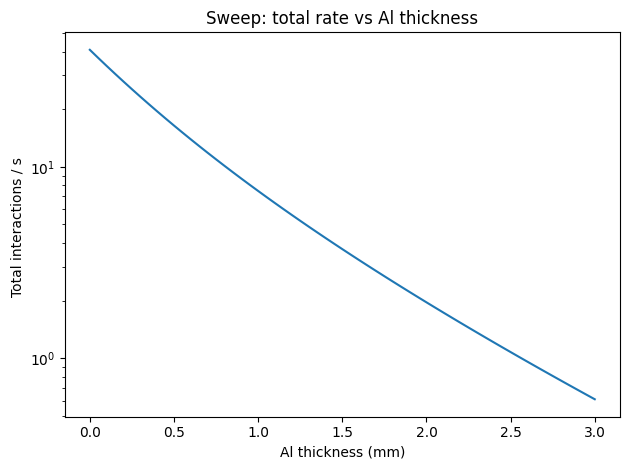

In [69]:
def show_table(rows, show_fe=True):
    """
    Display table of interaction rates.
    
    Args:
        rows: Output from compute_rates()
        show_fe: If True, show T_Fe column (only relevant if x_fe_mm > 0)
    """
    if show_fe:
        print(f"{'Line':<7} {'E (keV)':>8} {'Int%':>7} {'T_Fe':>10} {'T_Al':>10} {'T_Total':>10} {'P_Si':>10} "
              f"{'Phot/s':>12} {'Int/s':>12} {'Int/hr':>12}")
        print("-"*110)
        for lab, E, inten, T_fe, T_al, T_tot, P, phot, ints, hr in rows:
            print(f"{lab:<7} {E:8.3f} {inten:7.3f} {T_fe:10.4g} {T_al:10.4g} {T_tot:10.4g} {P:10.4g} {phot:12.4g} {ints:12.4g} {hr:12.4g}")
    else:
        print(f"{'Line':<7} {'E (keV)':>8} {'Int%':>7} {'T_Al':>10} {'P_Si':>10} "
              f"{'Phot/s':>12} {'Int/s':>12} {'Int/hr':>12}")
        print("-"*90)
        for lab, E, inten, T_fe, T_al, T_tot, P, phot, ints, hr in rows:
            print(f"{lab:<7} {E:8.3f} {inten:7.3f} {T_al:10.4g} {P:10.4g} {phot:12.4g} {ints:12.4g} {hr:12.4g}")
    tot = sum(r[8] for r in rows)  # interactions/s is now at index 8
    print("-"*110 if show_fe else "-"*90)
    # print(f"{'TOTAL':<7} {'':>8} {'':>7} {'':>10} {'':>10} {'':>10 if show_fe else ''} {'':>10} {'':>12} {tot:12.4g} {tot*3600:12.4g}")
    print(f"{' ':<7} {' ':<8} ...")  # ✅ Works correctly

show_table(rows)

# Plot per-line interaction rate
# want to exclude the first line (Ba-133 K-shell)
# Skip the first line (Ba-133 K-shell) for plotting
E = np.array([r[1] for r in rows], float)
R = np.array([r[8] for r in rows], float)  # interactions/s is now at index 8

# E = np.array([r[1] for r in rows], float)
# R = np.array([r[6] for r in rows], float)

plt.figure()
plt.bar(np.arange(len(E)), R)
plt.xticks(np.arange(len(E)), [f"{e:.1f}" for e in E], rotation=45, ha="right")
plt.yscale("log")
plt.xlabel("Line energy [keV]")
plt.ylabel("Interaction Rate [1/s]")
plt.title("Am-241 per-line interaction rate")
plt.tight_layout()
plt.show()

# Sweep Al thickness
x_vals = np.linspace(0.0, 3.0, 61)  # mm
y_vals = []
for x_al in x_vals:
    _, rr = compute_rates(x_al_mm=float(x_al))
    y_vals.append(sum(r[8] for r in rr))  # interactions/s is now at index 8
y_vals = np.array(y_vals)

plt.figure()
plt.plot(x_vals, y_vals)
plt.yscale("log")
plt.xlabel("Al thickness (mm)")
plt.ylabel("Total interactions / s ")
plt.title("Sweep: total rate vs Al thickness")
plt.tight_layout()
plt.show()


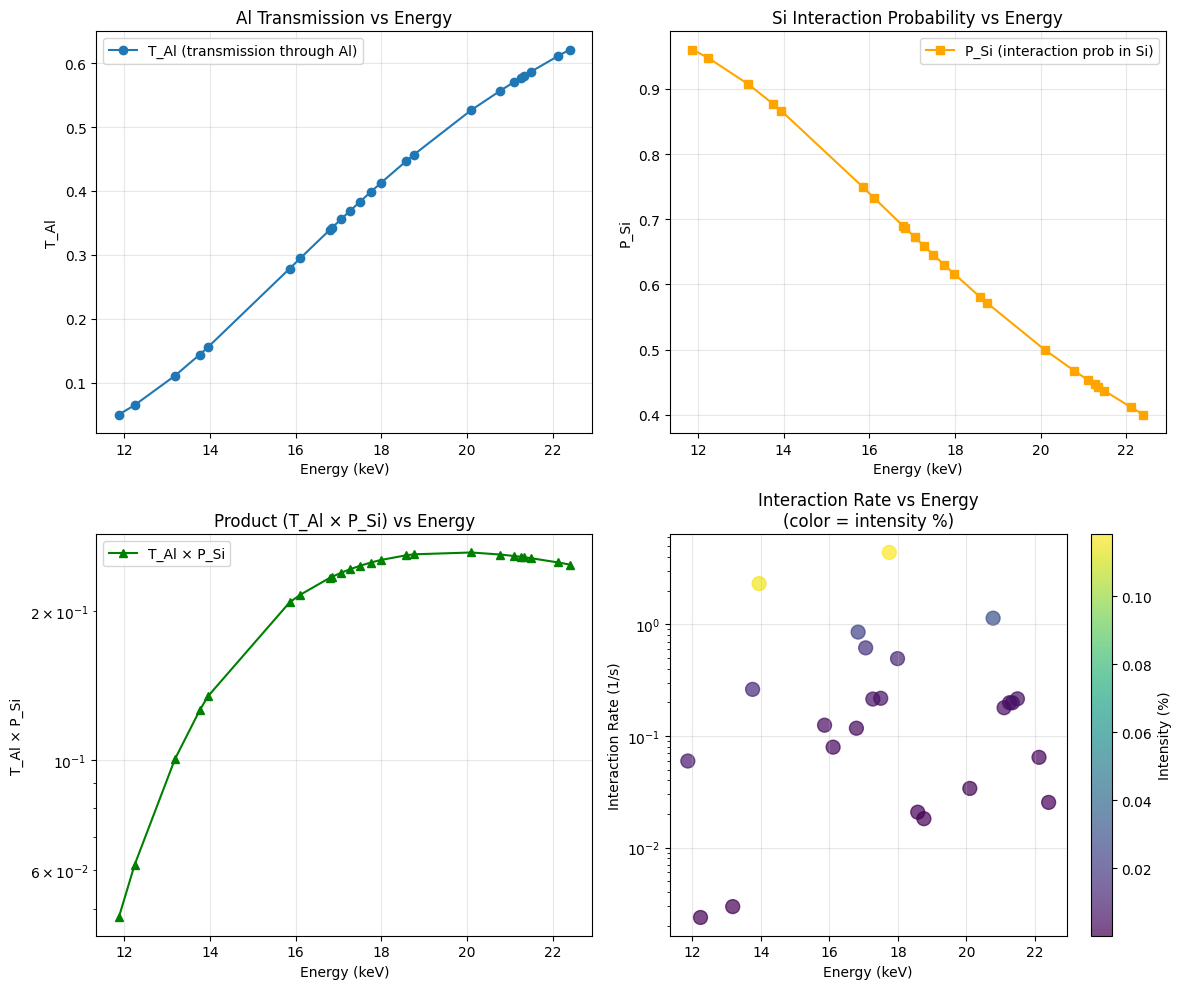


DETAILED BREAKDOWN: Why some high-energy lines have higher rates
Line         E(keV)     Int%    T_Total       P_Si        T×P       Rate/s     Rate/Int
----------------------------------------------------------------------------------------------------
L3-M1        11.870    0.837    0.05011     0.9603    0.04812      0.05964        7.125
L3-M2        12.240    0.026    0.06489     0.9476    0.06149     0.002367        9.106
L3-M3        13.180    0.020     0.1108      0.907     0.1005     0.002962        14.88
L3-M4        13.760    1.398      0.144     0.8768     0.1262       0.2613        18.69
L3-M5        13.950   11.600     0.1555     0.8662     0.1346        2.313        19.94
L2-M1        15.860    0.404     0.2786     0.7489     0.2086       0.1248        30.89
L3-N1        16.110    0.248     0.2949     0.7329     0.2161      0.07936           32
L3-N5        16.790    0.339     0.3387     0.6897     0.2336       0.1173        34.59
L3-N4        16.840    2.451     0.3419  

In [32]:
# DEBUG: Plot energy-dependent factors to understand why rate doesn't drop with energy
E_all = np.array([r[1] for r in rows], float)
T_fe_all = np.array([r[3] for r in rows], float)
T_al_all = np.array([r[4] for r in rows], float)
T_total_all = np.array([r[5] for r in rows], float)
P_si_all = np.array([r[6] for r in rows], float)  # P_Si is at index 6
I_all = np.array([r[2] for r in rows], float) / 100.0  # convert % to fraction
R_all = np.array([r[8] for r in rows], float)  # interactions/s is now at index 8

# Calculate the product T_Total * P_Si (now includes Fe if present)
T_P_product = T_total_all * P_si_all

# Calculate what the rate would be if intensity were constant
# R_normalized = R_all / I_all  # rate per unit intensity

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot 1: T_Al vs Energy
axes[0, 0].plot(E_all, T_al_all, 'o-', label='T_Al (transmission through Al)')
axes[0, 0].set_xlabel('Energy (keV)')
axes[0, 0].set_ylabel('T_Al')
axes[0, 0].set_title('Al Transmission vs Energy')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

# Plot 2: P_Si vs Energy
axes[0, 1].plot(E_all, P_si_all, 's-', color='orange', label='P_Si (interaction prob in Si)')
axes[0, 1].set_xlabel('Energy (keV)')
axes[0, 1].set_ylabel('P_Si')
axes[0, 1].set_title('Si Interaction Probability vs Energy')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

# Plot 3: T_Al * P_Si product vs Energy
axes[1, 0].plot(E_all, T_P_product, '^-', color='green', label='T_Al × P_Si')
axes[1, 0].set_xlabel('Energy (keV)')
axes[1, 0].set_ylabel('T_Al × P_Si')
axes[1, 0].set_title('Product (T_Al × P_Si) vs Energy')
axes[1, 0].set_yscale('log')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

# Plot 4: Interaction rate vs Energy (with intensity as color)
scatter = axes[1, 1].scatter(E_all, R_all, c=I_all, s=100, cmap='viridis', alpha=0.7)
axes[1, 1].set_xlabel('Energy (keV)')
axes[1, 1].set_ylabel('Interaction Rate (1/s)')
axes[1, 1].set_title('Interaction Rate vs Energy\n(color = intensity %)')
axes[1, 1].set_yscale('log')
axes[1, 1].grid(True, alpha=0.3)
plt.colorbar(scatter, ax=axes[1, 1], label='Intensity (%)')

plt.tight_layout()
plt.show()

# Print detailed breakdown for a few lines
print("\n" + "="*100)
print("DETAILED BREAKDOWN: Why some high-energy lines have higher rates")
print("="*100)
print(f"{'Line':<10} {'E(keV)':>8} {'Int%':>8} {'T_Total':>10} {'P_Si':>10} {'T×P':>10} {'Rate/s':>12} {'Rate/Int':>12}")
print("-"*100)
for r in rows:
    lab, E, inten, T_fe, T_al, T_tot, P, phot, ints, hr = r
    rate_per_int = ints / (inten/100.0) if inten > 0 else 0
    print(f"{lab:<10} {E:8.3f} {inten:8.3f} {T_tot:10.4g} {P:10.4g} {T_tot*P:10.4g} {ints:12.4g} {rate_per_int:12.4g}")

print("\n" + "="*100)
print("KEY INSIGHT: Rate = A × I × fΩ × T_Total × P_Si")
print("  - T_Total = T_Fe × T_Al (if Fe layer present)")
print("  - T_Total INCREASES with energy (less attenuation)")
print("  - P_Si DECREASES with energy (lower interaction prob)")
print("  - The product T_Total × P_Si should DECREASE with energy")
print("  - But intensity I varies dramatically between lines!")
print("="*100)


COMPARISON: With and without Fe layer

Without Fe layer (x_fe_mm=0.0):
  Total interaction rate: 11.83 /s = 4.261e+04 /hr

With Fe layer (x_fe_mm=1.0 mm, gap d_fe_al=0.5 cm):
  Total interaction rate: 1.797e-83 /s = 6.47e-80 /hr
  Reduction factor: 0.0000
  Geometry factor g: 0.0331 (vs 0.9871 without Fe)

Comparison table (first 5 lines):
Line      E(keV)       T_Fe       T_Al    T_Total       Rate/s       Rate/s
                                                       (no Fe)     (1mm Fe)
----------------------------------------------------------------------------------------------------
L3-M1     11.870          0    0.05011          0      0.05964            0
L3-M2     12.240          0    0.06489          0     0.002367            0
L3-M3     13.180          0     0.1108          0     0.002962            0
L3-M4     13.760 1.411e-308      0.144 2.031e-309       0.2613   1.237e-310
L3-M5     13.950 2.192e-297     0.1555 3.407e-298        2.313   1.701e-298


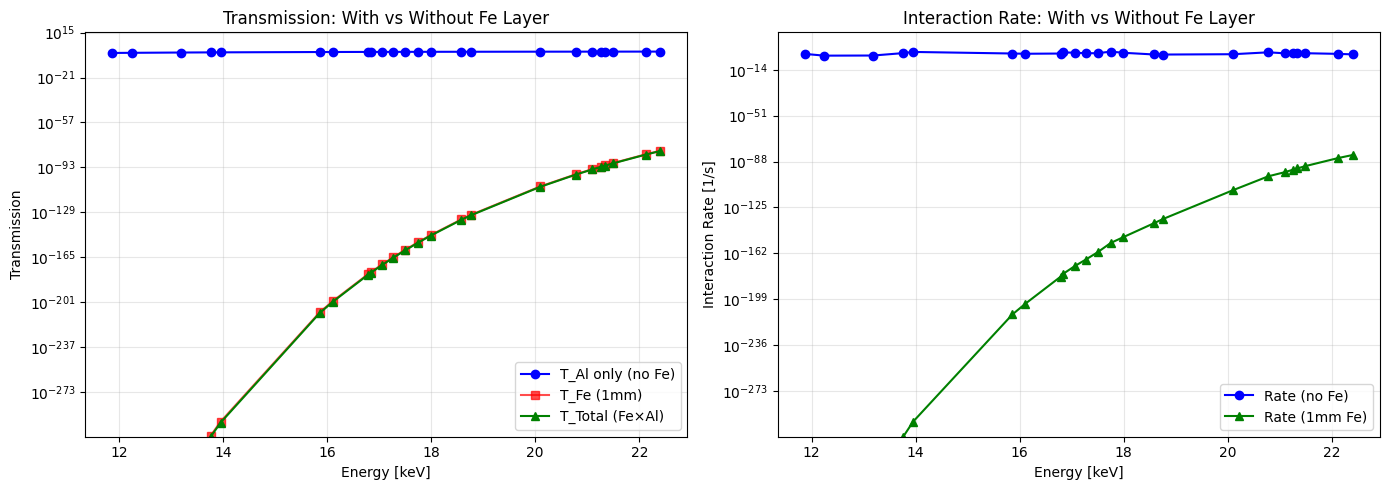


NOTE: Fe layer significantly attenuates low-energy photons
      High-energy photons are less affected by Fe attenuation


In [ ]:
# ============================================================================
# OPTION: Include Fe layer between source and Al (Source -> Fe -> Al -> Si)
# ============================================================================
print("COMPARISON: With and without Fe layer")
print("="*100)

# Calculate rates without Fe layer (original)
g_no_fe, rows_no_fe = compute_rates(x_fe_mm=0.0)
total_no_fe = sum(r[8] for r in rows_no_fe)

# Calculate rates with Fe layer (e.g., 1 mm Fe, with 0.5 cm gap to Al)
# Source -> Fe (taped, d_cm=0) -> gap (d_fe_al_cm=0.5) -> Al -> Si
g_with_fe, rows_with_fe = compute_rates(x_fe_mm=12.5, d_cm=0.0, d_fe_al_cm=20.0)
total_with_fe = sum(r[8] for r in rows_with_fe)

print(f"\nWithout Fe layer (x_fe_mm=0.0):")
print(f"  Total interaction rate: {total_no_fe:.4g} /s = {total_no_fe*3600:.4g} /hr")

print(f"\nWith Fe layer (x_fe_mm=1.0 mm, gap d_fe_al=0.5 cm):")
print(f"  Total interaction rate: {total_with_fe:.4g} /s = {total_with_fe*3600:.4g} /hr")
print(f"  Reduction factor: {total_with_fe/total_no_fe:.4f}")
print(f"  Geometry factor g: {g_with_fe:.4f} (vs {g_no_fe:.4f} without Fe)")

print("\n" + "="*100)
print("Comparison table (first 5 lines):")
print(f"{'Line':<7} {'E(keV)':>8} {'T_Fe':>10} {'T_Al':>10} {'T_Total':>10} {'Rate/s':>12} {'Rate/s':>12}")
print(f"{' ':<7} {' ':<8} {' ':<10} {' ':<10} {' ':<10} {'(no Fe)':>12} {'(1mm Fe)':>12}")
print("-"*100)
for i in range(min(5, len(rows_no_fe))):
    lab, E, inten, _, T_al_no, T_tot_no, _, _, ints_no, _ = rows_no_fe[i]
    _, _, _, T_fe, T_al_yes, T_tot_yes, _, _, ints_yes, _ = rows_with_fe[i]
    print(f"{lab:<7} {E:8.3f} {T_fe:10.4g} {T_al_yes:10.4g} {T_tot_yes:10.4g} {ints_no:12.4g} {ints_yes:12.4g}")

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Transmission comparison
E_no_fe = np.array([r[1] for r in rows_no_fe], float)
T_total_no_fe = np.array([r[5] for r in rows_no_fe], float)  # T_total = T_al when no Fe
T_total_with_fe = np.array([r[5] for r in rows_with_fe], float)
T_fe_vals = np.array([r[3] for r in rows_with_fe], float)

axes[0].plot(E_no_fe, T_total_no_fe, 'o-', label='T_Al only (no Fe)', color='blue')
axes[0].plot(E_no_fe, T_fe_vals, 's-', label='T_Fe (1mm)', color='red', alpha=0.7)
axes[0].plot(E_no_fe, T_total_with_fe, '^-', label='T_Total (Fe×Al)', color='green')
axes[0].set_xlabel('Energy [keV]')
axes[0].set_ylabel('Transmission')
axes[0].set_title('Transmission: With vs Without Fe Layer')
axes[0].grid(True, alpha=0.3)
axes[0].legend()
axes[0].set_yscale('log')

# Plot 2: Rate comparison
R_no_fe = np.array([r[8] for r in rows_no_fe], float)
R_with_fe = np.array([r[8] for r in rows_with_fe], float)

axes[1].plot(E_no_fe, R_no_fe, 'o-', label='Rate (no Fe)', color='blue')
axes[1].plot(E_no_fe, R_with_fe, '^-', label='Rate ( Fe)', color='green')
axes[1].set_xlabel('Energy [keV]')
axes[1].set_ylabel('Interaction Rate [1/s]')
axes[1].set_title('Interaction Rate: With vs Without Fe Layer')
axes[1].grid(True, alpha=0.3)
axes[1].legend()
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

print("\n" + "="*100)
print("NOTE: Fe layer significantly attenuates low-energy photons")
print("      High-energy photons are less affected by Fe attenuation")
print("="*100)


In [36]:
# CHECK: Should we use μen/ρ instead of μ/ρ for interaction probability?
# For counting interactions, μ/ρ (total attenuation) is correct
# For energy deposition, μen/ρ (energy absorption) would be used
# Let's compare both to see if there's a significant difference

print("="*100)
print("COMPARISON: Using μ/ρ vs μen/ρ for Si interaction probability")
print("="*100)
print(f"{'Line':<10} {'E(keV)':>8} {'μ/ρ':>12} {'μen/ρ':>12} {'P(μ/ρ)':>12} {'P(μen/ρ)':>12} {'Ratio':>10}")
print("-"*100)

# for lab, E_keV, inten_pct in BA133_LINES: 
for lab, E_keV, inten_pct in AM241_LINES:
    muor_si = xcom_si.mu_over_rho_at(E_keV)
    muenor_si = xcom_si.mu_en_over_rho_at(E_keV)
    
    t_si_cm = um_to_cm(675.0)
    P_mu = p_interact(muor_si, RHO_SI, t_si_cm)
    P_muen = p_interact(muenor_si, RHO_SI, t_si_cm)
    
    ratio = P_muen / P_mu if P_mu > 0 else 0
    print(f"{lab:<10} {E_keV:8.3f} {muor_si:12.4g} {muenor_si:12.4g} {P_mu:12.4g} {P_muen:12.4g} {ratio:10.4g}")

print("\nNOTE: For counting interactions (not energy deposition), μ/ρ is correct.")
print("      μen/ρ would be used if we cared about energy deposited, not just interactions.")


COMPARISON: Using μ/ρ vs μen/ρ for Si interaction probability
Line         E(keV)          μ/ρ        μen/ρ       P(μ/ρ)     P(μen/ρ)      Ratio
----------------------------------------------------------------------------------------------------
L3-M1        11.870        20.52        19.71       0.9603       0.9549     0.9944
L3-M2        12.240        18.75        17.98       0.9476       0.9409     0.9929
L3-M3        13.180         15.1        14.41        0.907       0.8964     0.9883
L3-M4        13.760        13.31        12.67       0.8768       0.8638     0.9852
L3-M5        13.950        12.79        12.17       0.8662       0.8524     0.9841
L2-M1        15.860        8.787        8.264       0.7489       0.7274     0.9713
L3-N1        16.110        8.394        7.879       0.7329       0.7104     0.9692
L3-N5        16.790         7.44        6.946       0.6897       0.6646     0.9637
L3-N4        16.840        7.376        6.884       0.6865       0.6613     0.9633
L1-M2  

EXAMPLE: Source at 1.0 cm from Al lid (not taped, no Fe layer)
g (separated) = 0.8074 (vs g (taped) = 0.9871)
Reduction factor: 0.8179

Total interaction rate (separated): 9.68 /s
Total interaction rate (taped):      11.83 /s
Ratio (sep/taped): 0.8179

SWEEP: Total interaction rate vs source distance from lid


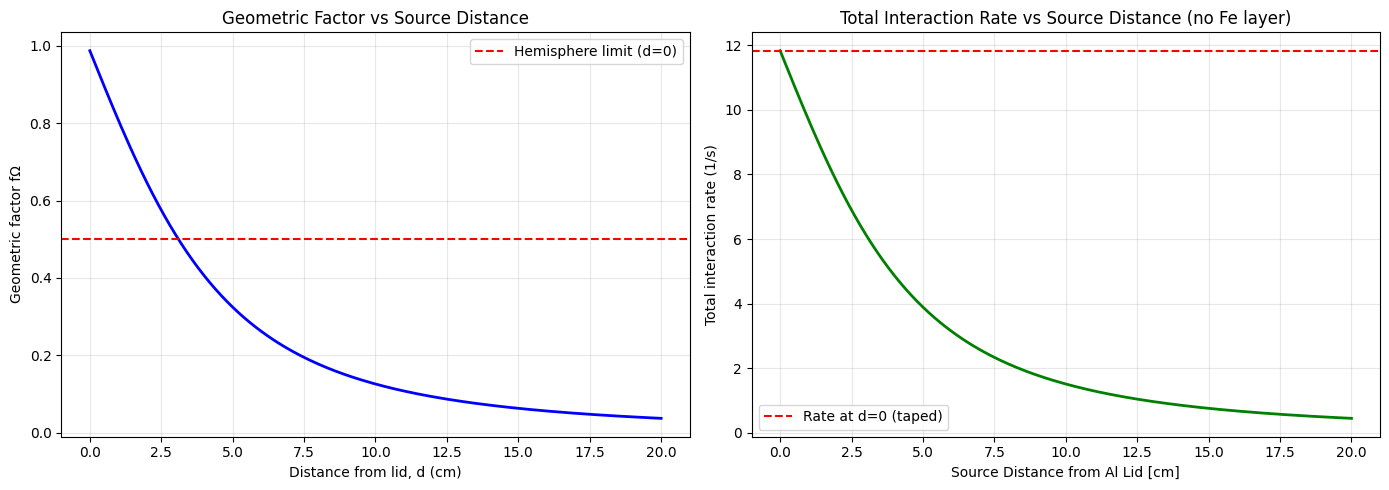


Distance (cm)   fΩ         Total Rate (1/s)     Rate/Rate(d=0) 
------------------------------------------------------------
0.00            0.9871     11.83                1.0000         
1.00            0.8074     9.68                 0.8179         
2.00            0.6460     7.745                0.6544         
3.00            0.5120     6.138                0.5187         
4.00            0.4061     4.869                0.4114         
5.00            0.3245     3.89                 0.3287         

USAGE: To calculate rates with source at distance d from lid (no Fe layer):
  g, rows = compute_rates(d_cm=your_distance_in_cm, x_fe_mm=0.0)

With Fe layer (source taped to Fe, gap to Al):
  g, rows = compute_rates(d_cm=0.0, x_fe_mm=thickness_mm, d_fe_al_cm=gap_cm)


In [37]:
# ============================================================================
# OPTION: Calculate rates with source separated from Al lid (d_cm > 0)
# ============================================================================

# Example: Source at 1 cm from lid (no Fe layer)
print("="*100)
print("EXAMPLE: Source at 1.0 cm from Al lid (not taped, no Fe layer)")
print("="*100)
fO_sep, rows_sep = compute_rates(d_cm=1.0, x_fe_mm=0.0)  # No Fe layer
print(f"g (separated) = {fO_sep:.4f} (vs g (taped) = {g:.4f})")
print(f"Reduction factor: {fO_sep/g:.4f}")
print(f"\nTotal interaction rate (separated): {sum(r[8] for r in rows_sep):.4g} /s")  # index 8
print(f"Total interaction rate (taped):      {sum(r[8] for r in rows):.4g} /s")  # index 8
print(f"Ratio (sep/taped): {sum(r[8] for r in rows_sep)/sum(r[8] for r in rows):.4f}")

# Sweep distance parameter
print("\n" + "="*100)
print("SWEEP: Total interaction rate vs source distance from lid")
print("="*100)
d_vals = np.linspace(0.0, 20.0, 201)  # cm
fO_vals = []
rate_vals = []
for d_cm in d_vals:
    fO, rr = compute_rates(d_cm=float(d_cm), x_fe_mm=0.0)  # No Fe layer
    fO_vals.append(fO)
    rate_vals.append(sum(r[8] for r in rr))  # interactions/s is at index 8
fO_vals = np.array(fO_vals)
rate_vals = np.array(rate_vals)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Geometric factor fΩ vs distance
axes[0].plot(d_vals, fO_vals, 'b-', linewidth=2)
axes[0].axhline(y=0.5, color='r', linestyle='--', label='Hemisphere limit (d=0)')
axes[0].set_xlabel('Distance from lid, d (cm)')
axes[0].set_ylabel('Geometric factor fΩ')
axes[0].set_title('Geometric Factor vs Source Distance')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Plot 2: Total interaction rate vs distance
axes[1].plot(d_vals, rate_vals, 'g-', linewidth=2)
axes[1].axhline(y=sum(r[8] for r in rows), color='r', linestyle='--', label='Rate at d=0 (taped)')  # index 8
axes[1].set_xlabel('Source Distance from Al Lid [cm]')
axes[1].set_ylabel('Total interaction rate (1/s)')
axes[1].set_title('Total Interaction Rate vs Source Distance (no Fe layer)')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# Print table for a few distances
print(f"\n{'Distance (cm)':<15} {'fΩ':<10} {'Total Rate (1/s)':<20} {'Rate/Rate(d=0)':<15}")
print("-"*60)
for i in [0, 10, 20, 30, 40, 50]:
    d = d_vals[i]
    fO = fO_vals[i]
    rate = rate_vals[i]
    ratio = rate / rate_vals[0] if rate_vals[0] > 0 else 0
    print(f"{d:<15.2f} {fO:<10.4f} {rate:<20.4g} {ratio:<15.4f}")

print("\n" + "="*100)
print("USAGE: To calculate rates with source at distance d from lid (no Fe layer):")
print("  g, rows = compute_rates(d_cm=your_distance_in_cm, x_fe_mm=0.0)")
print("\nWith Fe layer (source taped to Fe, gap to Al):")
print("  g, rows = compute_rates(d_cm=0.0, x_fe_mm=thickness_mm, d_fe_al_cm=gap_cm)")
print("="*100)


SWEEP: Individual energy line rates vs source distance


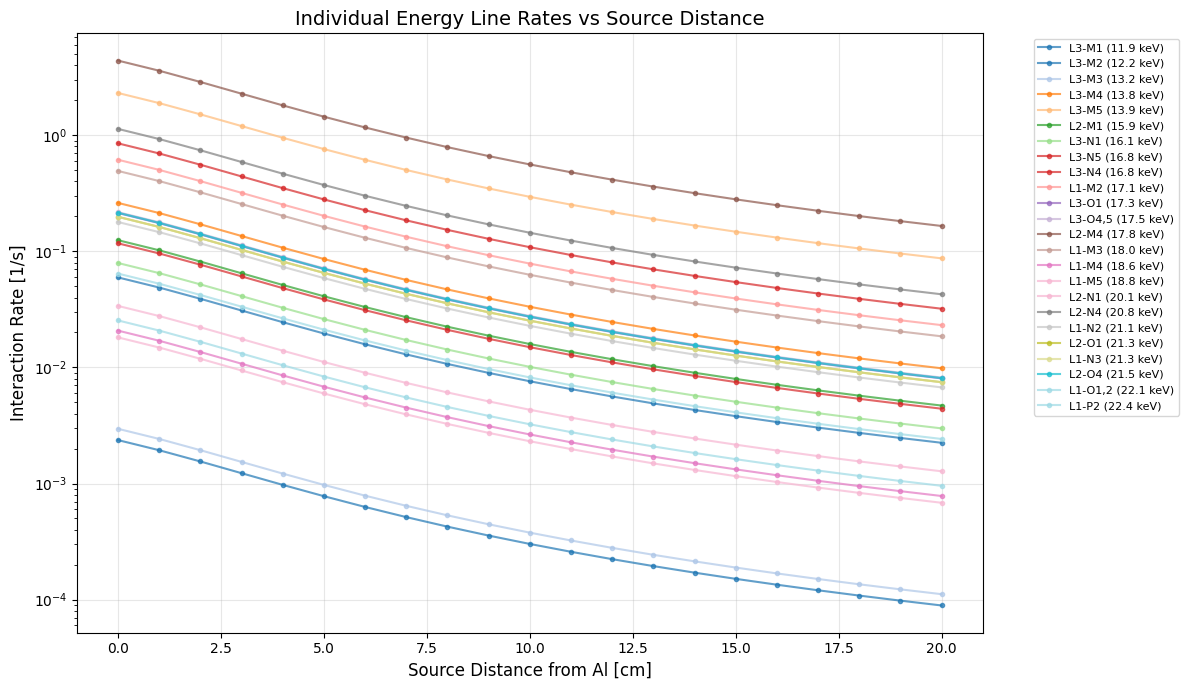


NOTE: All lines scale proportionally with distance (same fΩ factor)
      because the geometric factor fΩ is energy-independent.


In [40]:
# ============================================================================
# OPTION: Sweep distance for individual energy lines
# ============================================================================

# Sweep distance and track individual line rates
print("="*100)
print("SWEEP: Individual energy line rates vs source distance")
print("="*100)

d_vals = np.linspace(0.0, 20.0, 21)  # cm
line_rates_by_distance = {}  # {(label, energy): [rates at each distance]}

# Initialize dictionary with line labels and energies
# for lab, E_keV, _ in BA133_LINES:
for lab, E_keV, _ in AM241_LINES:
    line_rates_by_distance[(lab, E_keV)] = []

# Calculate rates at each distance
for d_cm in d_vals:
    _, rr = compute_rates(d_cm=float(d_cm), x_fe_mm=0.0)  # No Fe layer
    for lab, E_keV, _, _, _, _, _, _, ints, _ in rr:  # interactions/s is at index 8
        line_rates_by_distance[(lab, E_keV)].append(ints)

# Convert to numpy arrays
for key in line_rates_by_distance:
    line_rates_by_distance[key] = np.array(line_rates_by_distance[key])

# Plot all lines with their energies for labeling
fig, ax = plt.subplots(figsize=(12, 7))
# Use tab20 colormap which has 20 distinct colors, or viridis for continuous colors
# colors = plt.cm.tab20(np.linspace(0, 1, len(BA133_LINES)))
colors = plt.cm.tab20(np.linspace(0, 1, len(AM241_LINES)))


# for idx, (lab, E_keV, _) in enumerate(BA133_LINES):
for idx, (lab, E_keV, _) in enumerate(AM241_LINES):
    key = (lab, E_keV)
    if key in line_rates_by_distance:
        rates = line_rates_by_distance[key]
        # Create label with energy
        label = f"{lab} ({E_keV:.1f} keV)"
        ax.plot(d_vals, rates, 'o-', label=label, color=colors[idx], 
                markersize=3, linewidth=1.5, alpha=0.7)

ax.set_xlabel('Source Distance from Al [cm]', fontsize=12)
ax.set_ylabel('Interaction Rate [1/s]', fontsize=12)
ax.set_title('Individual Energy Line Rates vs Source Distance', fontsize=14)
ax.set_yscale('log')
# ax.set_ylim(1e-3, 2e1)
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8, ncol=1)
plt.tight_layout()
plt.show()

# # Print table showing how a few key lines change
# print(f"\n{'Distance':<12} {'XR Ka1 (31.0 keV)':<20} {'g (356.0 keV)':<20} {'g (81.0 keV)':<20}")
# print("-"*72)
# for i in [0, 5, 10, 15, 20]:
#     d = d_vals[i]
#     # Find rates for these specific lines by matching energy (no Fe layer)
#     _, rr = compute_rates(d_cm=float(d), x_fe_mm=0.0)
#     xr_ka1_rate = next((r[8] for r in rr if r[0] == 'XR Ka1'), 0)  # index 8
#     g_356_rate = next((r[8] for r in rr if abs(r[1] - 356.013) < 0.1), 0)  # index 8
#     g_81_rate = next((r[8] for r in rr if abs(r[1] - 80.998) < 0.1), 0)  # index 8
#     print(f"{d:<12.2f} {xr_ka1_rate:<20.4g} {g_356_rate:<20.4g} {g_81_rate:<20.4g}")



print("\nNOTE: All lines scale proportionally with distance (same fΩ factor)")
print("      because the geometric factor fΩ is energy-independent.")


SWEEP: Individual energy line rates vs Al lid thickness (d=0, source taped)


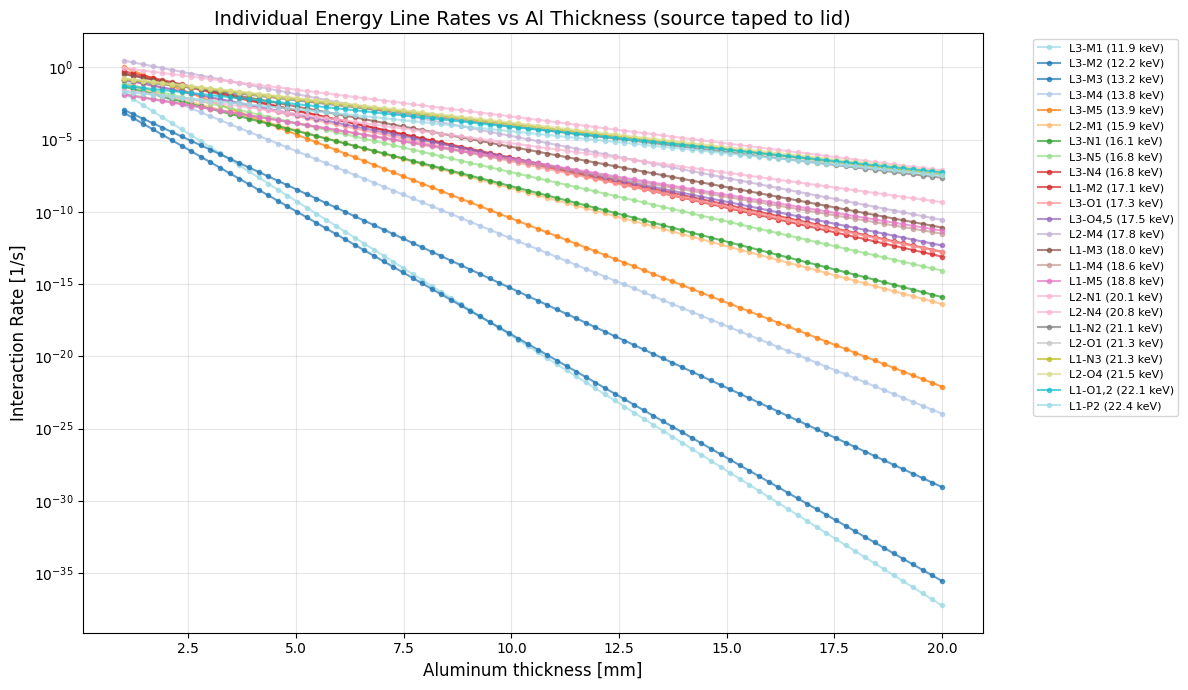

In [42]:
# ============================================================================
# OPTION: Sweep aluminum thickness for individual energy lines (d=0)
# ============================================================================

# Sweep Al thickness and track individual line rates
print("="*100)
print("SWEEP: Individual energy line rates vs Al lid thickness (d=0, source taped)")
print("="*100)

x_al_vals = np.linspace(1.0, 20.0, 86)  # mm
line_rates_by_thickness = {}  # {(label, energy): [rates at each thickness]}

# Initialize dictionary with line labels and energies
# for lab, E_keV, _ in BA133_LINES:
for lab, E_keV, _ in AM241_LINES:
    line_rates_by_thickness[(lab, E_keV)] = []

# Calculate rates at each Al thickness (no Fe layer, source taped to lid)
for x_al_mm in x_al_vals:
    _, rr = compute_rates(d_cm=0.0, x_al_mm=float(x_al_mm), x_fe_mm=0.0)  # No Fe layer
    for lab, E_keV, _, _, _, _, _, _, ints, _ in rr:  # interactions/s is at index 8
        line_rates_by_thickness[(lab, E_keV)].append(ints)

# Convert to numpy arrays
for key in line_rates_by_thickness:
    line_rates_by_thickness[key] = np.array(line_rates_by_thickness[key])

# Plot all lines with their energies for labeling (skip first line)
fig, ax = plt.subplots(figsize=(12, 7))
# colors = plt.cm.tab20(np.linspace(0, 1, len(BA133_LINES)))  # Skip first line
colors = plt.cm.tab20(np.linspace(0, 1, len(AM241_LINES)))  # Skip first line


# for idx, (lab, E_keV, _) in enumerate(BA133_LINES):  # Start from index 1
for idx, (lab, E_keV, _) in enumerate(AM241_LINES):  # Start from index 1
    key = (lab, E_keV)
    if key in line_rates_by_thickness:
        rates = line_rates_by_thickness[key]
        # Create label with energy
        label = f"{lab} ({E_keV:.1f} keV)"
        ax.plot(x_al_vals, rates, 'o-', label=label, color=colors[idx-1], 
                markersize=3, linewidth=1.5, alpha=0.7)

ax.set_xlabel('Aluminum thickness [mm]', fontsize=12)
ax.set_ylabel('Interaction Rate [1/s]', fontsize=12)
ax.set_title('Individual Energy Line Rates vs Al Thickness (source taped to lid)', fontsize=14)
ax.set_yscale('log')
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8, ncol=1)
plt.tight_layout()
plt.show()

# # Print table showing how a few key lines change
# print(f"\n{'Al Thick (mm)':<15} {'XR Ka1 (31.0 keV)':<20} {'g (356.0 keV)':<20} {'g (81.0 keV)':<20}")
# print("-"*75)
# for i in [0, 9, 18, 27, 36, 45]:
#     x_al = x_al_vals[i]
#     # Find rates for these specific lines
#     _, rr = compute_rates(d_cm=0.0, x_al_mm=float(x_al), x_fe_mm=0.0)  # No Fe layer
#     xr_ka1_rate = next((r[8] for r in rr if r[0] == 'XR Ka1'), 0)  # index 8
#     g_356_rate = next((r[8] for r in rr if abs(r[1] - 356.013) < 0.1), 0)  # index 8
#     g_81_rate = next((r[8] for r in rr if abs(r[1] - 80.998) < 0.1), 0)  # index 8
#     print(f"{x_al:<15.2f} {xr_ka1_rate:<20.4g} {g_356_rate:<20.4g} {g_81_rate:<20.4g}")

# print("\nNOTE: Lower energy lines are more strongly attenuated by Al than higher energy lines.")
# print("      This is why the X-ray lines (30-36 keV) drop faster than gamma lines (80-356 keV).")


THREE MODULE SETUP: Source at left-most lid

Module   Distance (cm) # Lids   Al (mm)    fΩ         Rate (1/s)      Rate (1/hr)    
-------------------------------------------------------------------------------------
1        0.00         1        0.70       0.0331     1.797e-83       6.47e-80       
2        2.00         3        2.10       0.0276     5.78e-84        2.081e-80      
3        4.00         5        3.50       0.0234     1.886e-84       6.791e-81      


/var/folders/kg/25wkj9w94_9_61jgr3vf6hyh0000gn/T/ipykernel_60032/3875803494.py:159: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()


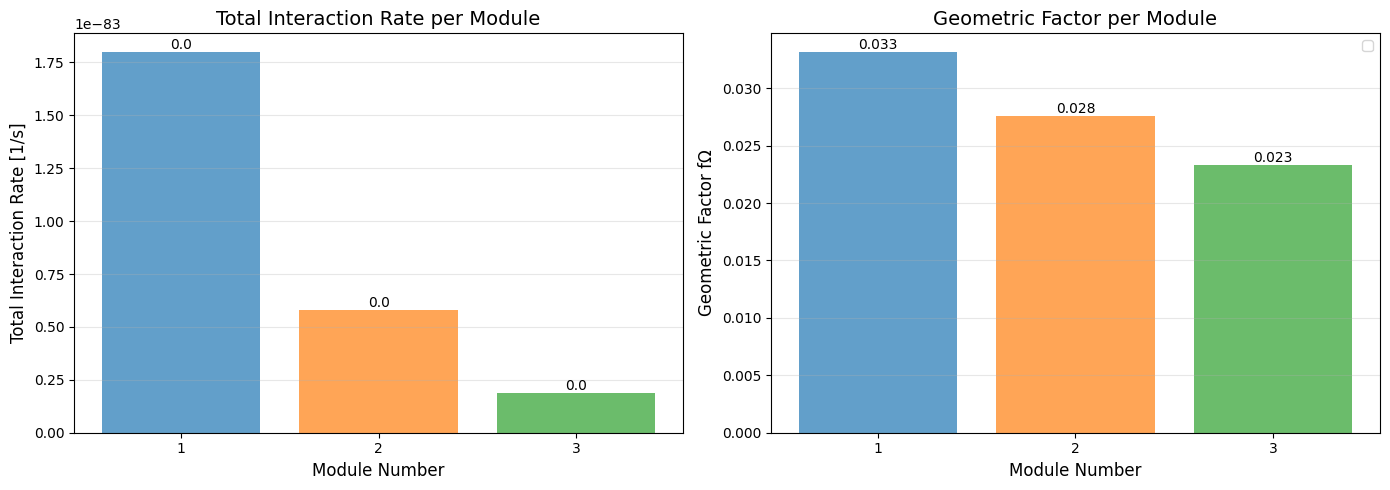


DETAILED BREAKDOWN BY MODULE

Left module (source taped to Fe):
  Distance from source: 0.00 cm
  Number of Al lids: 1
  Cumulative Al thickness: 0.70 mm
  Geometric factor fΩ: 0.0331
  Total rate: 1.797e-83 /s (6.47e-80 /hr)
  Top 8 contributing lines:
    1. L1-P2 (22.4 keV): 1.791e-83 /s (6.449e-80 /hr)
    2. L1-O1,2 (22.1 keV): 5.982e-86 /s (2.154e-82 /hr)
    3. L2-O4 (21.5 keV): 1.929e-92 /s (6.945e-89 /hr)
    4. L1-N3 (21.3 keV): 2.89e-94 /s (1.04e-90 /hr)
    5. L2-O1 (21.3 keV): 3.077e-95 /s (1.108e-91 /hr)
    6. L1-N2 (21.1 keV): 2.838e-97 /s (1.022e-93 /hr)
    7. L2-N4 (20.8 keV): 1.25e-100 /s (4.502e-97 /hr)
    8. L2-N1 (20.1 keV): 7.501e-112 /s (2.7e-108 /hr)

Module 2 (source at 2.0 cm):
  Distance from source: 2.00 cm
  Number of Al lids: 3
  Cumulative Al thickness: 2.10 mm
  Geometric factor fΩ: 0.0276
  Total rate: 5.78e-84 /s (2.081e-80 /hr)
  Top 8 contributing lines:
    1. L1-P2 (22.4 keV): 5.762e-84 /s (2.074e-80 /hr)
    2. L1-O1,2 (22.1 keV): 1.861e-86 /s

In [62]:
# ============================================================================
# THREE MODULE SETUP: Source at left-most lid, calculate rates in each module
# ============================================================================

print("="*100)
print("THREE MODULE SETUP: Source at left-most lid")
print("="*100)

# Geometry parameters
MODULE_WIDTH_CM = 2  # cm (width of each CCD module, adjust as needed)
SOURCE_POSITION = "left_lid"  # Source is at the left-most lid (d=0 for module 1)

# Setup: source + lid + Si + lid + lid + Si + lid + lid + Si + lid
# Module 1: photons pass through 1 lid (its own lid)
# Module 2: photons pass through 3 lids (module 1 lid + 2 lids between modules)
# Module 3: photons pass through 5 lids (module 1 lid + 2 lids between 1-2 + 2 lids between 2-3)

# Optimal parameters (you can adjust these)
OPTIMAL_PARAMS = dict(
    activity_kBq=0.3,
    disk_diam_cm=2.5,
    d_cm_source=0.0,  # Distance from source to first lid (or to Fe if Fe layer present)
    x_fe_mm=12.5,  # Fe layer thickness (0 = no Fe layer)
    d_fe_al_cm=20.0,  # Distance between Fe layer and Al lid (gap, only relevant if x_fe_mm > 0)
    x_al_mm=0.7,  # Thickness of each individual lid
    al_attenuator_mm=0,  # Thickness of the aluminum attenuator
    t_si_um=675.0,
    eps=1.0
)

# Number of lids photons must pass through to reach each module
LIDS_PER_MODULE = {
    1: 1,  # Module 1: 1 lid (its own)
    2: 3,  # Module 2: 1 (module 1) + 2 (between modules)
    3: 5   # Module 3: 1 (module 1) + 2 (between 1-2) + 2 (between 2-3)
}

# Calculate rates for each module
# Distance calculation follows the same logic as compute_rates():
# - If Fe layer: d_total = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm
# - If no Fe: d_total = d_cm + x_al_cm
module_results = []
for module_num in [1, 2, 3]:
    if module_num == 1:
        d_cm = OPTIMAL_PARAMS['d_cm_source']  # Distance from source to first lid (or Fe if present)
        if OPTIMAL_PARAMS['x_fe_mm'] > 0:
            description = "Left module (source taped to Fe)"
        else:
            description = "Left module (source at lid)"
    else:
        # For modules 2 and 3, calculate distance from source to this module's Al lid
        # The Fe layer (if present) is at the source position, so ALL modules pass through it
        # Path for Module 2/3: Source -> Fe -> gap -> module spacing -> Al of this module
        # compute_rates() calculates: d_total = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm (if Fe)
        # For Module 2/3 with Fe: we want d_total = x_fe_cm + d_fe_al_cm + spacing + x_al_cm
        # So we pass: d_cm = spacing (MODULE_WIDTH_CM * (module_num - 1))
        # compute_rates() will add: spacing + x_fe_cm + d_fe_al_cm + x_al_cm ✓
        if OPTIMAL_PARAMS['x_fe_mm'] > 0:
            # Source -> Fe (at source) -> gap -> module spacing -> Al of this module
            # d_cm = module spacing only (Fe and gap will be added by compute_rates)
            d_cm = MODULE_WIDTH_CM * (module_num - 1)
        else:
            # Source -> (module spacing) -> Al of this module
            d_cm = OPTIMAL_PARAMS['d_cm_source'] + MODULE_WIDTH_CM * (module_num - 1)
        description = f"Module {module_num} (source at {d_cm:.1f} cm)"
    
    # Total Al thickness = number of lids × thickness per lid
    num_lids = LIDS_PER_MODULE[module_num]
    total_al_thickness_mm = num_lids * OPTIMAL_PARAMS['x_al_mm'] + OPTIMAL_PARAMS['al_attenuator_mm']
    
    # Use Fe layer parameters appropriately:
    # ALL modules pass through Fe layer if it's present (since Fe is at source)
    # The difference is the distance calculation:
    # - Module 1: d_cm = distance from source to Fe (typically 0)
    # - Modules 2/3: d_cm = distance from source to where Al starts = Fe + gap + spacing
    # compute_rates() calculates d_total using the same logic (lines 174-179):
    # - If Fe: d_total = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm
    # - If no Fe: d_total = d_cm + x_al_cm
    if OPTIMAL_PARAMS['x_fe_mm'] > 0:
        # Fe layer is present at source - ALL modules must pass through it
        x_fe_for_module = OPTIMAL_PARAMS['x_fe_mm']
        d_fe_al_for_module = OPTIMAL_PARAMS['d_fe_al_cm']
        if module_num == 1:
            # Module 1: Source is at Fe (d_cm_source typically 0 if taped)
            d_cm_for_compute = OPTIMAL_PARAMS['d_cm_source']
            # compute_rates() will calculate: d_total = 0 + x_fe_cm + d_fe_al_cm + x_al_cm ✓
        else:
            # Modules 2/3: Source -> Fe -> gap -> spacing -> Al
            # We pass d_cm = spacing (MODULE_WIDTH_CM * (module_num - 1))
            # compute_rates() will calculate: d_total = spacing + x_fe_cm + d_fe_al_cm + x_al_cm ✓
            d_cm_for_compute = MODULE_WIDTH_CM * (module_num - 1)
    else:
        # No Fe layer
        x_fe_for_module = 0.0
        d_fe_al_for_module = 0.0
        if module_num == 1:
            d_cm_for_compute = OPTIMAL_PARAMS['d_cm_source']
        else:
            d_cm_for_compute = OPTIMAL_PARAMS['d_cm_source'] + MODULE_WIDTH_CM * (module_num - 1)
    
    fO, rows = compute_rates(
        d_cm=d_cm_for_compute,
        x_al_mm=total_al_thickness_mm,  # Cumulative Al thickness
        x_fe_mm=x_fe_for_module,  # Fe layer parameter (applies to ALL modules if Fe present)
        d_fe_al_cm=d_fe_al_for_module,  # Gap parameter (applies to ALL modules if Fe present)
        activity_kBq=OPTIMAL_PARAMS['activity_kBq'],
        disk_diam_cm=OPTIMAL_PARAMS['disk_diam_cm'],
        t_si_um=OPTIMAL_PARAMS['t_si_um'],
        eps=OPTIMAL_PARAMS['eps']
    )
    
    total_rate = sum(r[8] for r in rows)  # interactions/s is at index 8
    
    module_results.append({
        'module': module_num,
        'd_cm': d_cm,
        'num_lids': num_lids,
        'total_al_mm': total_al_thickness_mm,
        'fO': fO,
        'description': description,
        'total_rate_per_s': total_rate,
        'total_rate_per_hr': total_rate * 3600,
        'rows': rows
    })

# Print summary table
print(f"\n{'Module':<8} {'Distance (cm)':<12} {'# Lids':<8} {'Al (mm)':<10} {'fΩ':<10} {'Rate (1/s)':<15} {'Rate (1/hr)':<15}")
print("-"*85)
for result in module_results:
    print(f"{result['module']:<8} {result['d_cm']:<12.2f} {result['num_lids']:<8} "
          f"{result['total_al_mm']:<10.2f} {result['fO']:<10.4f} "
          f"{result['total_rate_per_s']:<15.4g} {result['total_rate_per_hr']:<15.4g}")

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Total rates per module
modules = [r['module'] for r in module_results]
rates = [r['total_rate_per_s'] for r in module_results]
fOs = [r['fO'] for r in module_results]

axes[0].bar(modules, rates, color=['#1f77b4', '#ff7f0e', '#2ca02c'], alpha=0.7)
axes[0].set_xlabel('Module Number', fontsize=12)
axes[0].set_ylabel(f'Total Interaction Rate [1/s]', fontsize=12)
axes[0].set_title('Total Interaction Rate per Module', fontsize=14)
axes[0].set_xticks(modules)
axes[0].grid(True, alpha=0.3, axis='y')
for i, (m, r) in enumerate(zip(modules, rates)):
    axes[0].text(m, r, f'{r:.1f}', ha='center', va='bottom', fontsize=10)

# Plot 2: Geometric factor fΩ per module
axes[1].bar(modules, fOs, color=['#1f77b4', '#ff7f0e', '#2ca02c'], alpha=0.7)
# axes[1].axhline(y=0.5, color='r', linestyle='--', label='Hemisphere limit (d=0)')
axes[1].set_xlabel('Module Number', fontsize=12)
axes[1].set_ylabel('Geometric Factor fΩ', fontsize=12)
axes[1].set_title('Geometric Factor per Module', fontsize=14)
axes[1].set_xticks(modules)
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].legend()
for i, (m, f) in enumerate(zip(modules, fOs)):
    axes[1].text(m, f, f'{f:.3f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Detailed breakdown for each module
print("\n" + "="*100)
print("DETAILED BREAKDOWN BY MODULE")
print("="*100)

for result in module_results:
    print(f"\n{result['description']}:")
    print(f"  Distance from source: {result['d_cm']:.2f} cm")
    print(f"  Number of Al lids: {result['num_lids']}")
    print(f"  Cumulative Al thickness: {result['total_al_mm']:.2f} mm")
    print(f"  Geometric factor fΩ: {result['fO']:.4f}")
    print(f"  Total rate: {result['total_rate_per_s']:.4g} /s ({result['total_rate_per_hr']:.4g} /hr)")
    
    # Show top 8 contributing lines
    sorted_rows = sorted(result['rows'], key=lambda r: r[8], reverse=True)  # Sort by interactions/s at index 8
    print(f"  Top 8 contributing lines:")
    for i, (lab, E, inten, T_fe, T_al, T_tot, P, phot, ints, hr) in enumerate(sorted_rows[:8], 1):
        print(f"    {i}. {lab} ({E:.1f} keV): {ints:.4g} /s ({hr:.4g} /hr)")

print("\n" + "="*100)
print("NOTE: Adjust MODULE_WIDTH_CM if your modules have different spacing.")
print("="*100)


THREE MODULE SETUP: TWO SOURCES (left + right)
Combining results from left-source and right-source configurations

Module   From Left (1/s)    From Right (1/s)   Total (1/s)     Total (1/hr)   
--------------------------------------------------------------------------------
1        1.959              0.03857            1.997           7190           
2        0.2555             0.2555             0.511           1840           
3        0.03857            1.959              1.997           7190           


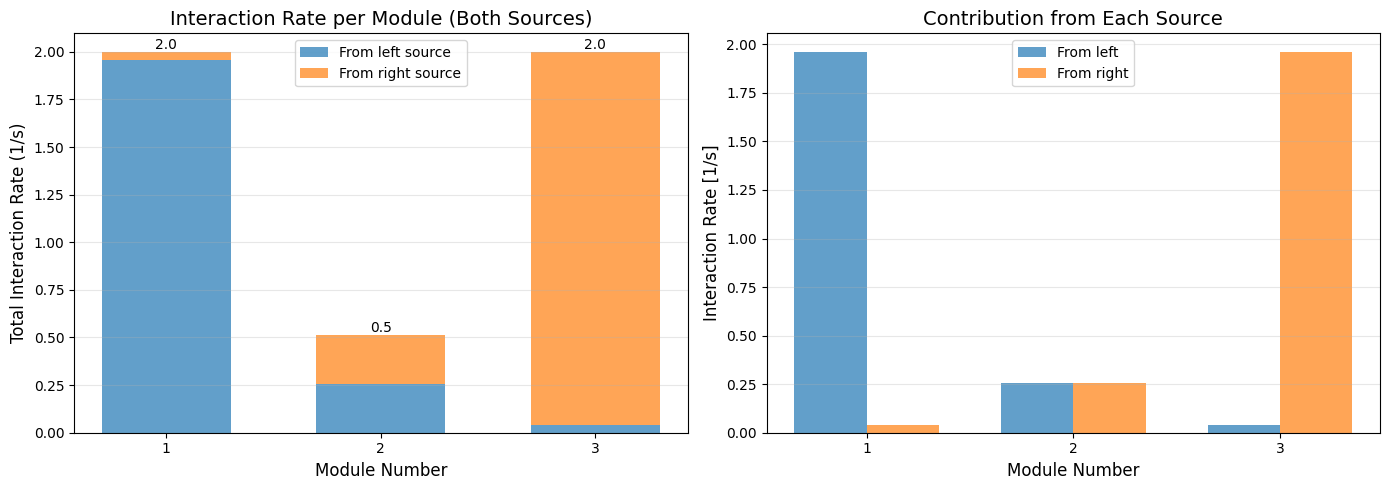


DETAILED BREAKDOWN BY MODULE (Both Sources Combined)

Module 1:
  Rate from left source:  1.959 /s
  Rate from right source: 0.03857 /s
  Total rate: 1.997 /s (7190 /hr)
  Top 5 contributing lines (combined from both sources):
    1. L2-M4 (17.8 keV): 0.7834 /s (2820 /hr)
    2. L2-N4 (20.8 keV): 0.387 /s (1393 /hr)
    3. L3-N4 (16.8 keV): 0.1138 /s (409.9 /hr)
    4. L1-M3 (18.0 keV): 0.0939 /s (338.1 /hr)
    5. L1-M2 (17.1 keV): 0.08862 /s (319 /hr)

Module 2:
  Rate from left source:  0.2555 /s
  Rate from right source: 0.2555 /s
  Total rate: 0.511 /s (1840 /hr)
  Top 5 contributing lines (combined from both sources):
    1. L2-M4 (17.8 keV): 0.1551 /s (558.2 /hr)
    2. L2-N4 (20.8 keV): 0.1458 /s (525.1 /hr)
    3. L2-O4 (21.5 keV): 0.03376 /s (121.5 /hr)
    4. L1-N3 (21.3 keV): 0.02987 /s (107.5 /hr)
    5. L2-O1 (21.3 keV): 0.02928 /s (105.4 /hr)

Module 3:
  Rate from left source:  0.03857 /s
  Rate from right source: 1.959 /s
  Total rate: 1.997 /s (7190 /hr)
  Top 5 cont

In [65]:
# ============================================================================
# THREE MODULE SETUP: TWO SOURCES (one at left, one at right)
# ============================================================================

print("="*100)
print("THREE MODULE SETUP: TWO SOURCES (left + right)")
print("="*100)
print("Combining results from left-source and right-source configurations")
print("="*100)

# Same geometry parameters as cell 12
MODULE_WIDTH_CM = 2.0  # cm (width of each CCD module, adjust as needed)

# Optimal parameters (same as cell 12)
# Optimal parameters (you can adjust these)
OPTIMAL_PARAMS = dict(
    activity_kBq=0.3,
    disk_diam_cm=2.5,
    d_cm_source=0.0,  # Distance from source to first lid (or to Fe if Fe layer present)
    x_fe_mm=0,  # Fe layer thickness (0 = no Fe layer)
    d_fe_al_cm=0.0,  # Distance between Fe layer and Al lid (gap, only relevant if x_fe_mm > 0)
    x_al_mm=0.7,  # Thickness of each individual lid
    al_attenuator_mm=1.3,  # Thickness of the aluminum attenuator
    t_si_um=675.0,
    eps=1.0
)

# Calculate LEFT source results
# Distance calculation follows the same logic as compute_rates():
# - If Fe layer: d_total = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm
# - If no Fe: d_total = d_cm + x_al_cm
LIDS_PER_MODULE_LEFT = {
    1: 1,  # Module 1: 1 lid (its own)
    2: 3,  # Module 2: 1 (module 1) + 2 (between modules)
    3: 5   # Module 3: 1 (module 1) + 2 (between 1-2) + 2 (between 2-3)
}

module_results_left = []
for module_num in [1, 2, 3]:
    if module_num == 1:
        d_cm = OPTIMAL_PARAMS['d_cm_source']  # Distance from source to first lid (or Fe if present)
    else:
        # For modules 2 and 3, calculate distance from source to this module's Al lid
        # The Fe layer (if present) is at the source position, so ALL modules pass through it
        # Path: Source -> Fe -> gap -> module spacing -> Al of this module
        if OPTIMAL_PARAMS['x_fe_mm'] > 0:
            # Source -> Fe (at source) -> gap -> module spacing -> Al of this module
            # d_cm = module spacing only (Fe and gap will be added by compute_rates)
            d_cm = MODULE_WIDTH_CM * (module_num - 1)
        else:
            d_cm = MODULE_WIDTH_CM * (module_num - 1) + OPTIMAL_PARAMS['d_cm_source']
    
    num_lids = LIDS_PER_MODULE_LEFT[module_num]
    total_al_thickness_mm = num_lids * OPTIMAL_PARAMS['x_al_mm'] + OPTIMAL_PARAMS['al_attenuator_mm']
    
    # Use Fe layer parameters appropriately (same logic as Cell 14):
    # ALL modules pass through Fe layer if it's present (since Fe is at source)
    # The difference is the distance calculation:
    # - Module 1: d_cm = distance from source to Fe (typically 0)
    # - Modules 2/3: d_cm = module spacing (Fe + gap added by compute_rates)
    # compute_rates() calculates d_total using the same logic (lines 174-179):
    # - If Fe: d_total = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm
    # - If no Fe: d_total = d_cm + x_al_cm
    if OPTIMAL_PARAMS['x_fe_mm'] > 0:
        # Fe layer is present at source - ALL modules must pass through it
        x_fe_for_module = OPTIMAL_PARAMS['x_fe_mm']
        d_fe_al_for_module = OPTIMAL_PARAMS['d_fe_al_cm']
        if module_num == 1:
            d_cm_for_compute = OPTIMAL_PARAMS['d_cm_source']
        else:
            d_cm_for_compute = MODULE_WIDTH_CM * (module_num - 1)
    else:
        # No Fe layer
        x_fe_for_module = 0.0
        d_fe_al_for_module = 0.0
        if module_num == 1:
            d_cm_for_compute = OPTIMAL_PARAMS['d_cm_source']
        else:
            d_cm_for_compute = MODULE_WIDTH_CM * (module_num - 1) + OPTIMAL_PARAMS['d_cm_source']
    
    fO, rows = compute_rates(
        d_cm=d_cm_for_compute,
        x_al_mm=total_al_thickness_mm,
        x_fe_mm=x_fe_for_module,  # Fe layer parameter (applies to ALL modules if Fe present)
        d_fe_al_cm=d_fe_al_for_module,  # Gap parameter (applies to ALL modules if Fe present)
        activity_kBq=OPTIMAL_PARAMS['activity_kBq'],
        disk_diam_cm=OPTIMAL_PARAMS['disk_diam_cm'],
        t_si_um=OPTIMAL_PARAMS['t_si_um'],
        eps=OPTIMAL_PARAMS['eps']
    )
    
    total_rate = sum(r[8] for r in rows)  # interactions/s is at index 8
    module_results_left.append({
        'module': module_num,
        'total_rate_per_s': total_rate,
        'total_rate_per_hr': total_rate * 3600,
        'rows': rows
    })

# Calculate RIGHT source results (mirror of left)
# Distance calculation follows the same logic as compute_rates():
# - If Fe layer: d_total = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm
# - If no Fe: d_total = d_cm + x_al_cm
LIDS_PER_MODULE_RIGHT = {
    3: 1,  # Module 3: 1 lid (its own)
    2: 3,  # Module 2: 1 (module 3) + 2 (between modules)
    1: 5   # Module 1: 1 (module 3) + 2 (between 3-2) + 2 (between 2-1)
}

module_results_right = []
for module_num in [3, 2, 1]:
    if module_num == 3:
        d_cm = OPTIMAL_PARAMS['d_cm_source']  # Distance from source to first lid (or Fe if present)
    else:
        # For modules 2 and 1, calculate distance from source to this module's Al lid
        # The Fe layer (if present) is at the source position, so ALL modules pass through it
        # Path: Source -> Fe -> gap -> module spacing -> Al of this module
        if OPTIMAL_PARAMS['x_fe_mm'] > 0:
            # Source -> Fe (at source) -> gap -> module spacing -> Al of this module
            # d_cm = module spacing only (Fe and gap will be added by compute_rates)
            d_cm = MODULE_WIDTH_CM * (3 - module_num)
        else:
            d_cm = OPTIMAL_PARAMS['d_cm_source'] + MODULE_WIDTH_CM * (3 - module_num)
    
    num_lids = LIDS_PER_MODULE_RIGHT[module_num]
    total_al_thickness_mm = num_lids * OPTIMAL_PARAMS['x_al_mm'] + OPTIMAL_PARAMS['al_attenuator_mm']
    
    # Use Fe layer parameters appropriately (same logic as Cell 14):
    # ALL modules pass through Fe layer if it's present (since Fe is at source)
    # The difference is the distance calculation:
    # - Module 3: d_cm = distance from source to Fe (typically 0)
    # - Modules 2/1: d_cm = module spacing (Fe + gap added by compute_rates)
    # compute_rates() calculates d_total using the same logic (lines 174-179):
    # - If Fe: d_total = d_cm + x_fe_cm + d_fe_al_cm + x_al_cm
    # - If no Fe: d_total = d_cm + x_al_cm
    if OPTIMAL_PARAMS['x_fe_mm'] > 0:
        # Fe layer is present at source - ALL modules must pass through it
        x_fe_for_module = OPTIMAL_PARAMS['x_fe_mm']
        d_fe_al_for_module = OPTIMAL_PARAMS['d_fe_al_cm']
        if module_num == 3:
            d_cm_for_compute = OPTIMAL_PARAMS['d_cm_source']
        else:
            d_cm_for_compute = MODULE_WIDTH_CM * (3 - module_num)
    else:
        # No Fe layer
        x_fe_for_module = 0.0
        d_fe_al_for_module = 0.0
        if module_num == 3:
            d_cm_for_compute = OPTIMAL_PARAMS['d_cm_source']
        else:
            d_cm_for_compute = OPTIMAL_PARAMS['d_cm_source'] + MODULE_WIDTH_CM * (3 - module_num)
    
    fO, rows = compute_rates(
        d_cm=d_cm_for_compute,
        x_al_mm=total_al_thickness_mm,
        x_fe_mm=x_fe_for_module,  # Fe layer parameter (applies to ALL modules if Fe present)
        d_fe_al_cm=d_fe_al_for_module,  # Gap parameter (applies to ALL modules if Fe present)
        activity_kBq=OPTIMAL_PARAMS['activity_kBq'],
        disk_diam_cm=OPTIMAL_PARAMS['disk_diam_cm'],
        t_si_um=OPTIMAL_PARAMS['t_si_um'],
        eps=OPTIMAL_PARAMS['eps']
    )
    
    total_rate = sum(r[8] for r in rows)  # interactions/s is at index 8
    module_results_right.append({
        'module': module_num,
        'total_rate_per_s': total_rate,
        'total_rate_per_hr': total_rate * 3600,
        'rows': rows
    })

# Sort both by module number
module_results_left.sort(key=lambda x: x['module'])
module_results_right.sort(key=lambda x: x['module'])

# Combine results: sum rates from both sources for each module
module_results_combined = []
for i in range(3):
    left = module_results_left[i]
    right = module_results_right[i]
    
    # Combine rows by summing interaction rates for each energy line
    combined_rows = []
    for (lab_l, E_l, inten_l, T_fe_l, T_al_l, T_tot_l, P_l, phot_l, ints_l, hr_l), \
        (lab_r, E_r, inten_r, T_fe_r, T_al_r, T_tot_r, P_r, phot_r, ints_r, hr_r) in zip(left['rows'], right['rows']):
        # Should have same energy, just sum the interaction rates
        # Use average transmission values (or could use left/right separately)
        combined_ints = ints_l + ints_r
        combined_rows.append((lab_l, E_l, inten_l, T_fe_l, T_al_l, T_tot_l, P_l, phot_l, combined_ints, combined_ints*3600))
    
    module_results_combined.append({
        'module': left['module'],
        'rate_from_left': left['total_rate_per_s'],
        'rate_from_right': right['total_rate_per_s'],
        'total_rate_per_s': left['total_rate_per_s'] + right['total_rate_per_s'],
        'total_rate_per_hr': (left['total_rate_per_s'] + right['total_rate_per_s']) * 3600,
        'rows': combined_rows
    })

# Print summary table
print(f"\n{'Module':<8} {'From Left (1/s)':<18} {'From Right (1/s)':<18} {'Total (1/s)':<15} {'Total (1/hr)':<15}")
print("-"*80)
for result in module_results_combined:
    print(f"{result['module']:<8} {result['rate_from_left']:<18.4g} {result['rate_from_right']:<18.4g} "
          f"{result['total_rate_per_s']:<15.4g} {result['total_rate_per_hr']:<15.4g}")

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Total rates per module (stacked bar showing contributions)
modules = [r['module'] for r in module_results_combined]
rates_left = [r['rate_from_left'] for r in module_results_combined]
rates_right = [r['rate_from_right'] for r in module_results_combined]
rates_total = [r['total_rate_per_s'] for r in module_results_combined]

x = np.arange(len(modules))
width = 0.6
axes[0].bar(x, rates_left, width, label='From left source', color='#1f77b4', alpha=0.7)
axes[0].bar(x, rates_right, width, bottom=rates_left, label='From right source', color='#ff7f0e', alpha=0.7)
axes[0].set_xlabel('Module Number', fontsize=12)
axes[0].set_ylabel('Total Interaction Rate (1/s)', fontsize=12)
axes[0].set_title('Interaction Rate per Module (Both Sources)', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels(modules)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')
for i, (m, r) in enumerate(zip(modules, rates_total)):
    axes[0].text(i, r, f'{r:.1f}', ha='center', va='bottom', fontsize=10)

# Plot 2: Comparison of contributions
x = np.arange(len(modules))
width = 0.35
axes[1].bar(x - width/2, rates_left, width, label='From left', color='#1f77b4', alpha=0.7)
axes[1].bar(x + width/2, rates_right, width, label='From right', color='#ff7f0e', alpha=0.7)
axes[1].set_xlabel('Module Number', fontsize=12)
axes[1].set_ylabel('Interaction Rate [1/s]', fontsize=12)
axes[1].set_title('Contribution from Each Source', fontsize=14)
axes[1].set_xticks(x)
axes[1].set_xticklabels(modules)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Detailed breakdown for each module
print("\n" + "="*100)
print("DETAILED BREAKDOWN BY MODULE (Both Sources Combined)")
print("="*100)

for result in module_results_combined:
    print(f"\nModule {result['module']}:")
    print(f"  Rate from left source:  {result['rate_from_left']:.4g} /s")
    print(f"  Rate from right source: {result['rate_from_right']:.4g} /s")
    print(f"  Total rate: {result['total_rate_per_s']:.4g} /s ({result['total_rate_per_hr']:.4g} /hr)")
    
    # Show top 5 contributing lines (from combined rates)
    sorted_rows = sorted(result['rows'], key=lambda r: r[8], reverse=True)  # Sort by interactions/s at index 8
    print(f"  Top 5 contributing lines (combined from both sources):")
    for i, (lab, E, inten, T_fe, T_al, T_tot, P, phot, ints, hr) in enumerate(sorted_rows[:5], 1):
        print(f"    {i}. {lab} ({E:.1f} keV): {ints:.4g} /s ({hr:.4g} /hr)")

print("\n" + "="*100)
print("NOTE: Rates are additive - each module receives photons from both sources.")
print("      Module 2 (middle) receives contributions from both sides.")
print("="*100)
